# IPL Team Performance Analysis – Data Analytics Case Study

**Team members:** _(write your names here)_
**Module:** Data Analytics

**Dataset:** IPL Complete Dataset (2008–2024), Kaggle, by Patrick B (`patrickb1912/ipl-complete-dataset-20082020`)
- `deliveries.csv` – one row per ball bowled (260,920 rows, 17 columns). **This is the main dataset.** Every performance measure in this study is calculated from it.
- `matches.csv` – one row per match (1,095 rows, 20 columns). Used **only** to find the `winner` of each match (and `team1`/`team2` to select the matches in scope).

**Contents**
1. Business problem
2. Data understanding, cleaning & preparation
3. Exploratory data analysis (EDA)
4. Team performance profiles (bivariate / multivariate analysis)
5. Hypothesis testing (4 hypotheses)
6. Business insights
7. Recommendations

## 1. Business Problem

IPL franchises spend crores every year at the player auction. To spend that money well, team management needs to know **where its team is strong, where it is weak, and what actually separates winning performances from losing ones.**

Win/loss alone is a poor measure: a team can lose after a good batting display, or win with an average one. Ball-by-ball data lets us measure *how* a team performs, not only *whether* it won.

**Scope:** the 8 long-running IPL franchises – Chennai Super Kings, Delhi Capitals, Kolkata Knight Riders, Mumbai Indians, Punjab Kings, Rajasthan Royals, Royal Challengers Bengaluru and Sunrisers Hyderabad – using only matches played between two of these teams. Gujarat Titans and Lucknow Super Giants are excluded because they joined only in 2022 and have far fewer matches, which would make comparisons unfair.

**Stakeholder:** franchise team management and auction strategy team.

**Questions we want to answer**
1. How do the 8 franchises compare in batting (run rate, dot balls) and bowling (economy, wickets, dot balls)?
2. In which phase of the innings (Powerplay, Middle, Death) is each team strong or weak?
3. Which on-field factors are linked to winning – and are those links statistically significant?

## 2. Data Understanding, Cleaning & Preparation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

In [ ]:
deliveries = pd.read_csv("deliveries.csv")
matches = pd.read_csv("matches.csv")

print("deliveries:", deliveries.shape, " - main dataset")
print("matches   :", matches.shape, " - only used to find the winner")

deliveries: (260920, 17)  <- main dataset
matches   : (1095, 20)  <- only used to find the winner


In [3]:
deliveries.head()

,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,extra_runs,total_runs,extras_type,is_wicket,player_dismissed,dismissal_kind,fielder
0,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,SC Ganguly,P Kumar,BB McCullum,0,1,1,legbyes,0,NaN,NaN,NaN
1,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
2,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,BB McCullum,P Kumar,SC Ganguly,0,1,1,wides,0,NaN,NaN,NaN
3,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,4,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
4,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,5,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN


In [4]:
deliveries.info()

<class 'pandas.DataFrame'>
RangeIndex: 260920 entries, 0 to 260919
Data columns (total 17 columns):
 #   Column            Non-Null Count   Dtype
---  ------            --------------   -----
 0   match_id          260920 non-null  int64
 1   inning            260920 non-null  int64
 2   batting_team      260920 non-null  str  
 3   bowling_team      260920 non-null  str  
 4   over              260920 non-null  int64
 5   ball              260920 non-null  int64
 6   batter            260920 non-null  str  
 7   bowler            260920 non-null  str  
 8   non_striker       260920 non-null  str  
 9   batsman_runs      260920 non-null  int64
 10  extra_runs        260920 non-null  int64
 11  total_runs        260920 non-null  int64
 12  extras_type       14125 non-null   str  
 13  is_wicket         260920 non-null  int64
 14  player_dismissed  12950 non-null   str  
 15  dismissal_kind    12950 non-null   str  
 16  fielder           9354 non-null    str  
dtypes: int64(8), str(9)
m

In [5]:
print("--- deliveries: missing values ---")
print(deliveries.isnull().sum()[deliveries.isnull().sum() > 0])
print()
print("--- matches: missing values ---")
print(matches.isnull().sum()[matches.isnull().sum() > 0])

--- deliveries: missing values ---
extras_type         246795
player_dismissed    247970
dismissal_kind      247970
fielder             251566
dtype: int64

--- matches: missing values ---
city                 51
player_of_match       5
winner                5
result_margin        19
target_runs           3
target_overs          3
method             1074
dtype: int64


**What the missing values mean**
- In `deliveries`, `extras_type`, `player_dismissed`, `dismissal_kind` and `fielder` are blank on most rows. These are **structural nulls**: they are blank because most balls are not extras and most balls are not wickets. They are *not* missing data, so we do not fill or drop them.
- In `matches`, `winner` is blank for no-result matches (e.g. rain). We remove them, because every innings in our study must be labelled as part of a win or a loss. Other columns of `matches` with blanks (`city`, `method`, …) are not used, so they need no cleaning.

**Cleaning steps**
1. Standardise franchise names that changed over the years (e.g. Delhi Daredevils → Delhi Capitals).
2. Keep only matches where **both teams** are among our 8 franchises.
3. Keep only matches with a result.
4. Keep only the two main innings (remove super overs, which are innings 3–6).
5. Check for duplicate rows.
6. Attach `winner` from `matches` to every ball.

In [6]:
# 1. same franchise, different names over the years
team_fix = {
    "Delhi Daredevils": "Delhi Capitals",
    "Kings XI Punjab": "Punjab Kings",
    "Royal Challengers Bangalore": "Royal Challengers Bengaluru",
}
for col in ["team1", "team2", "winner"]:
    matches[col] = matches[col].replace(team_fix)
for col in ["batting_team", "bowling_team"]:
    deliveries[col] = deliveries[col].replace(team_fix)

# 2. keep only matches between two of our 8 franchises
TEAMS = ["Chennai Super Kings", "Delhi Capitals", "Kolkata Knight Riders", "Mumbai Indians",
         "Punjab Kings", "Rajasthan Royals", "Royal Challengers Bengaluru", "Sunrisers Hyderabad"]
matches = matches[matches["team1"].isin(TEAMS) & matches["team2"].isin(TEAMS)].copy()
print("matches between our 8 teams:", len(matches))

# 3. keep only matches with a result
matches = matches[matches["winner"].notna()].copy()
print("matches with a result      :", len(matches))

# 4. remove super overs
deliveries = deliveries[deliveries["inning"].isin([1, 2])].copy()

# 5. duplicates
print("duplicate rows in deliveries:", deliveries.duplicated().sum())

# 6. attach the winner to every ball (inner join keeps only the matches we kept)
bb = deliveries.merge(matches[["id", "winner"]], left_on="match_id", right_on="id", how="inner")
bb = bb.drop(columns="id")
print("ball-by-ball rows used:", bb.shape)
print("teams:", sorted(bb["batting_team"].unique()))

matches between our 8 teams: 826
matches with a result      : 823
duplicate rows in deliveries: 0
ball-by-ball rows used: (196340, 18)
teams: ['Chennai Super Kings', 'Delhi Capitals', 'Kolkata Knight Riders', 'Mumbai Indians', 'Punjab Kings', 'Rajasthan Royals', 'Royal Challengers Bengaluru', 'Sunrisers Hyderabad']


### Creating new columns (feature engineering)
Cricket has a few rules that matter when we turn raw rows into statistics:
- **Legal ball:** wides and no-balls are not one of the 6 balls in an over. So **run rate = runs ÷ legal balls × 6**.
- **Runs charged to the bowler:** byes and leg byes are not the bowler's fault, so economy uses a separate `bowler_runs` column.
- **Wickets credited to the bowler:** run outs, retired and obstructing the field are not bowling wickets.
- **Dot ball:** a legal ball with no run scored.
- **Phase:** the `over` column starts at 0, so we add 1 first. Powerplay = overs 1–6, Middle = overs 7–15, Death = overs 16–20.

In [7]:
bb["legal"] = (~bb["extras_type"].isin(["wides", "noballs"])).astype(int)

bb["bowler_runs"] = np.where(bb["extras_type"].isin(["byes", "legbyes", "penalty"]),
                             bb["total_runs"] - bb["extra_runs"],
                             bb["total_runs"])

bb["is_dot"] = ((bb["total_runs"] == 0) & (bb["legal"] == 1)).astype(int)
bb["is_boundary"] = bb["batsman_runs"].isin([4, 6]).astype(int)

not_bowler_wkt = ["run out", "retired hurt", "retired out", "obstructing the field"]
bb["bowler_wkt"] = ((bb["is_wicket"] == 1) & (~bb["dismissal_kind"].isin(not_bowler_wkt))).astype(int)

bb["over_number"] = bb["over"] + 1
bb["phase"] = pd.cut(bb["over_number"], bins=[0, 6, 15, 20], labels=["Powerplay", "Middle", "Death"])

bb[["match_id", "inning", "batting_team", "over_number", "phase", "total_runs",
    "legal", "bowler_runs", "is_dot", "is_boundary", "bowler_wkt"]].head()

,match_id,inning,batting_team,over_number,phase,total_runs,legal,bowler_runs,is_dot,is_boundary,bowler_wkt
0,335982,1,Kolkata Knight Riders,1,Powerplay,1,1,0,0,0,0
1,335982,1,Kolkata Knight Riders,1,Powerplay,0,1,0,1,0,0
2,335982,1,Kolkata Knight Riders,1,Powerplay,1,0,1,0,0,0
3,335982,1,Kolkata Knight Riders,1,Powerplay,0,1,0,1,0,0
4,335982,1,Kolkata Knight Riders,1,Powerplay,0,1,0,1,0,0


### Innings-level table
One row per innings: runs, legal balls, wickets, dot balls, boundaries and Powerplay wickets. Each innings is labelled `won = 1` if the batting team went on to win the match. **This table is the base for the team analysis and all hypothesis tests.**

In [8]:
inn = (bb.groupby(["match_id", "inning", "batting_team", "winner"])
         .agg(runs=("total_runs", "sum"),
              balls=("legal", "sum"),
              wkts=("is_wicket", "sum"),
              dots=("is_dot", "sum"),
              boundaries=("is_boundary", "sum"))
         .reset_index())

# wickets lost in the Powerplay
pp_wkts = (bb[bb["phase"] == "Powerplay"]
             .groupby(["match_id", "inning"])["is_wicket"].sum()
             .reset_index(name="pp_wkts"))
inn = inn.merge(pp_wkts, on=["match_id", "inning"], how="left")
inn["pp_wkts"] = inn["pp_wkts"].fillna(0)

inn["won"] = (inn["batting_team"] == inn["winner"]).astype(int)
inn["run_rate"] = inn["runs"] / inn["balls"] * 6
inn["dot_pct"] = inn["dots"] / inn["balls"] * 100

print(inn.shape)
inn.head()

(1646, 13)


,match_id,inning,batting_team,winner,runs,balls,wkts,dots,boundaries,pp_wkts,won,run_rate,dot_pct
0,335982,1,Kolkata Knight Riders,Kolkata Knight Riders,222,120,3,36,29,1,1,11.100000,30.000000
1,335982,2,Royal Challengers Bengaluru,Kolkata Knight Riders,82,91,10,50,6,4,0,5.406593,54.945055
2,335983,1,Chennai Super Kings,Chennai Super Kings,240,120,5,34,36,1,1,12.000000,28.333333
3,335983,2,Punjab Kings,Chennai Super Kings,207,120,4,23,27,1,0,10.350000,19.166667
4,335984,1,Rajasthan Royals,Delhi Capitals,129,120,8,54,17,2,0,6.450000,45.000000


In [9]:
inn[["runs", "balls", "wkts", "run_rate", "dot_pct", "pp_wkts"]].describe().round(2)

,runs,balls,wkts,run_rate,dot_pct,pp_wkts
count,1646.00,1646.00,1646.00,1646.00,1646.00,1646.00
mean,159.33,114.93,5.89,8.34,36.08,1.41
std,32.68,11.97,2.45,1.54,7.51,1.11
min,44.00,26.00,0.00,3.82,15.83,0.00
25%,139.00,115.00,4.00,7.25,30.83,1.00
50%,160.00,120.00,6.00,8.25,35.29,1.00
75%,180.00,120.00,8.00,9.30,40.71,2.00
max,287.00,121.00,10.00,14.35,68.04,5.00


## 3. Exploratory Data Analysis (EDA)

**Part A – Match level** (how an IPL innings behaves)
1. Run rate and wickets in each over
2. Phase summary (Powerplay, Middle, Death)
3. Distribution of innings totals

**Part B – Team level** (how the 8 franchises compare)
1. Matches played, wins and win %
2. Distribution of innings totals by team
3. Fours and sixes per innings by team

### Part A – Match level

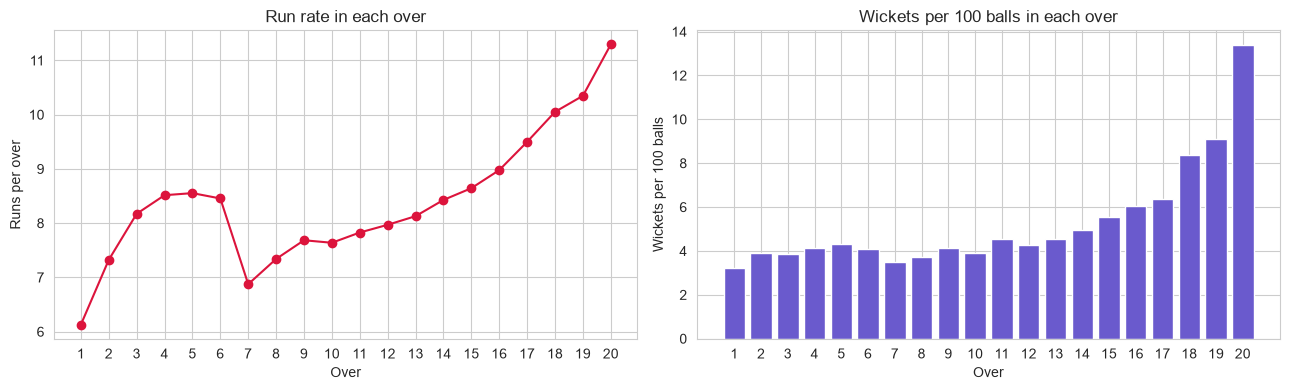

over_number,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
run_rate,6.13,7.32,8.17,8.52,8.55,8.45,6.88,7.34,7.68,7.64,7.83,7.97,8.13,8.43,8.64,8.98,9.50,10.05,10.35,11.29
wkts_per_100_balls,3.24,3.91,3.88,4.12,4.32,4.10,3.48,3.70,4.15,3.89,4.52,4.28,4.53,4.95,5.56,6.03,6.38,8.39,9.10,13.38


In [10]:
# A1. run rate and wicket rate in each over
by_over = bb.groupby("over_number").agg(runs=("total_runs", "sum"), balls=("legal", "sum"),
                                        wkts=("is_wicket", "sum"))
by_over["run_rate"] = by_over["runs"] / by_over["balls"] * 6
by_over["wkts_per_100_balls"] = by_over["wkts"] / by_over["balls"] * 100

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(by_over.index, by_over["run_rate"], marker="o", color="crimson")
ax[0].set_title("Run rate in each over")
ax[0].set_xlabel("Over"); ax[0].set_ylabel("Runs per over"); ax[0].set_xticks(range(1, 21))

ax[1].bar(by_over.index, by_over["wkts_per_100_balls"], color="slateblue")
ax[1].set_title("Wickets per 100 balls in each over")
ax[1].set_xlabel("Over"); ax[1].set_ylabel("Wickets per 100 balls"); ax[1].set_xticks(range(1, 21))
plt.tight_layout()
plt.show()

by_over[["run_rate", "wkts_per_100_balls"]].round(2).T

**Observation:** Scoring starts slowly (6.13 runs in over 1), climbs to about 8.5 by overs 4–6, then **drops sharply in over 7 (6.88)** when the fielding restrictions end. After that it rises steadily to **11.29 in over 20**. Wickets stay at about 3–5 per 100 balls until over 15, then shoot up to **13.38 per 100 balls in over 20**, because batters take more risks. This is why we split every innings into three phases.

In [11]:
# A2. phase summary
phase_tbl = bb.groupby("phase").agg(runs=("total_runs", "sum"), balls=("legal", "sum"),
                                                   wkts=("is_wicket", "sum"), dots=("is_dot", "sum"),
                                                   boundaries=("is_boundary", "sum"))
phase_tbl["run_rate"] = phase_tbl["runs"] / phase_tbl["balls"] * 6
phase_tbl["wkts_per_100_balls"] = phase_tbl["wkts"] / phase_tbl["balls"] * 100
phase_tbl["dot_%"] = phase_tbl["dots"] / phase_tbl["balls"] * 100
phase_tbl["boundary_%"] = phase_tbl["boundaries"] / phase_tbl["balls"] * 100
phase_tbl[["run_rate", "wkts_per_100_balls", "dot_%", "boundary_%"]].round(2)

,run_rate,wkts_per_100_balls,dot_%,boundary_%
phase,,,,
Powerplay,7.86,3.93,46.93,19.69
Middle,7.83,4.34,32.15,13.87
Death,9.96,8.41,28.67,20.42


**Observation:**
- The Powerplay (7.86) and Middle overs (7.83) score at almost the same rate. The **Death overs are about 2 runs per over faster (9.96)**.
- Wickets fall **twice as often** at the Death (8.41 per 100 balls vs about 4).
- Powerplay and Death hit boundaries at almost the same rate (19.7% vs 20.4%). The Death is faster because it has **far fewer dot balls** (28.7% vs 46.9%).
- The Middle overs have the fewest boundaries (13.9%) but keep pace with the Powerplay by rotating the strike (dot balls 32.2%).

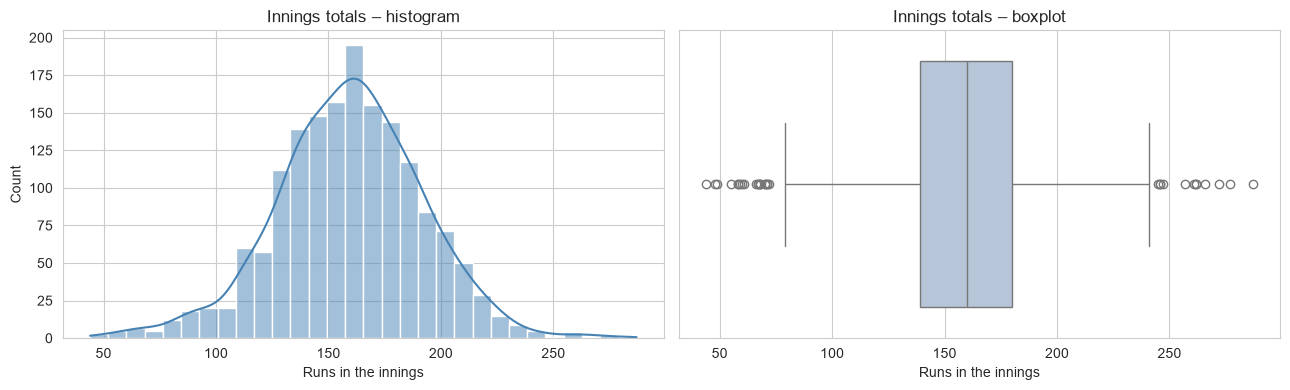

median: 160.0 | skewness: -0.12


In [12]:
# A3. distribution of innings totals
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(inn["runs"], bins=30, kde=True, ax=ax[0], color="steelblue")
ax[0].set_title("Innings totals – histogram")
ax[0].set_xlabel("Runs in the innings")
sns.boxplot(x=inn["runs"], ax=ax[1], color="lightsteelblue")
ax[1].set_title("Innings totals – boxplot")
ax[1].set_xlabel("Runs in the innings")
plt.tight_layout()
plt.show()

print("median:", inn["runs"].median(), "| skewness:", round(inn["runs"].skew(), 2))

**Observation:** A typical innings total is about **160 runs** (median). The distribution is bell-shaped and nearly symmetric (skewness -0.12). The dots in the boxplot are collapses, rain-shortened innings and very big scores – genuine events, so they are kept. The lowest total is 44, because no-result matches were removed during cleaning.

### Part B – Team level

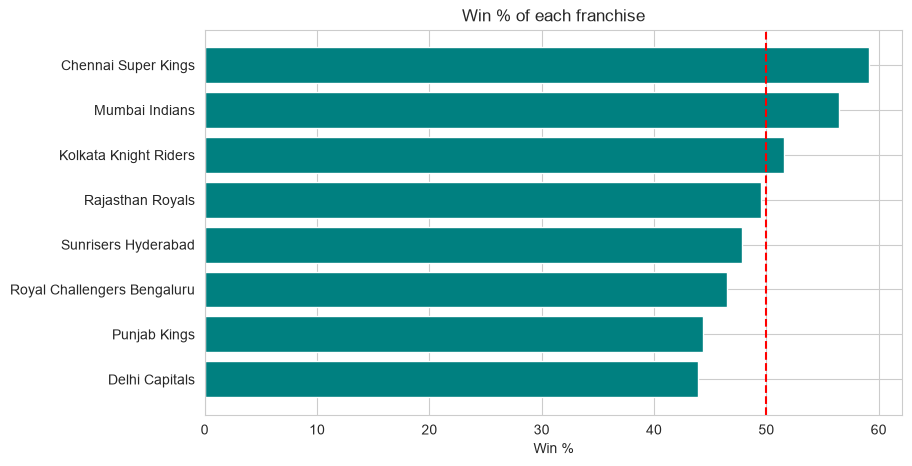

,matches,wins,win_%
batting_team,,,
Chennai Super Kings,208,123,59.1
Mumbai Indians,223,126,56.5
Kolkata Knight Riders,219,113,51.6
Rajasthan Royals,192,95,49.5
Sunrisers Hyderabad,163,78,47.9
Royal Challengers Bengaluru,215,100,46.5
Punjab Kings,212,94,44.3
Delhi Capitals,214,94,43.9


In [13]:
# B1. matches played, wins and win % (each team bats once per match, so innings = matches)
team_record = inn.groupby("batting_team").agg(matches=("won", "size"), wins=("won", "sum"))
team_record["win_%"] = team_record["wins"] / team_record["matches"] * 100
team_record = team_record.sort_values("win_%")

plt.figure(figsize=(9, 5))
plt.barh(team_record.index, team_record["win_%"], color="teal")
plt.axvline(50, color="red", linestyle="--")
plt.title("Win % of each franchise")
plt.xlabel("Win %")
plt.show()

team_record.sort_values("win_%", ascending=False).round(1)

**Observation:** Only **3 of the 8 franchises win more than half their matches**: Chennai Super Kings (59.1%), Mumbai Indians (56.5%) and Kolkata Knight Riders (51.6%). Delhi Capitals (43.9%) and Punjab Kings (44.3%) have the weakest records. Sunrisers Hyderabad have fewer matches (163) because they joined in 2013. Win % here counts only matches between these 8 teams.

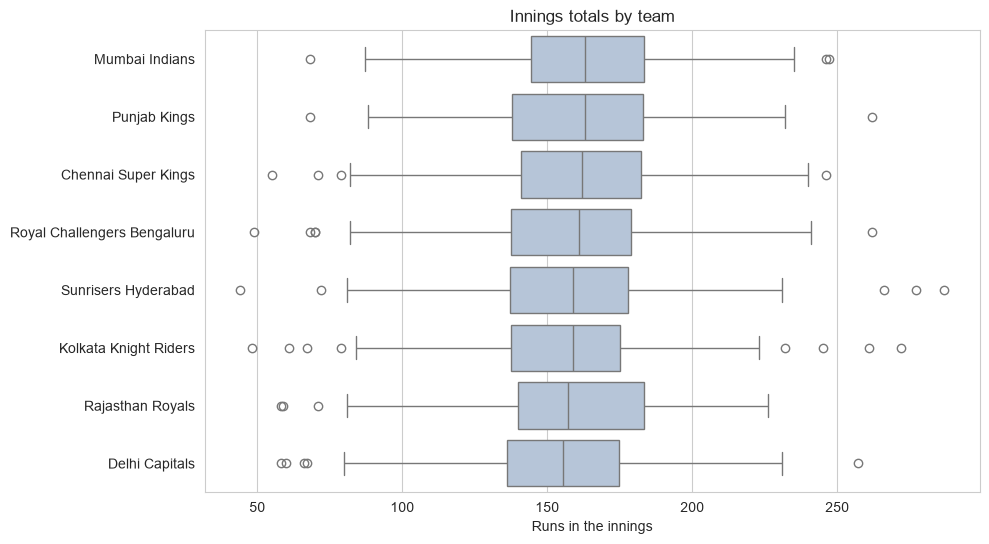

,median,mean,std
batting_team,,,
Mumbai Indians,163.0,162.4,31.3
Punjab Kings,163.0,161.4,32.1
Chennai Super Kings,162.0,162.5,31.7
Royal Challengers Bengaluru,161.0,158.5,34.1
Sunrisers Hyderabad,159.0,160.7,33.9
Kolkata Knight Riders,159.0,156.6,33.0
Rajasthan Royals,157.0,158.7,32.7
Delhi Capitals,155.5,154.3,32.4


In [14]:
# B2. distribution of innings totals for each team
order = inn.groupby("batting_team")["runs"].median().sort_values(ascending=False).index

plt.figure(figsize=(10, 6))
sns.boxplot(data=inn, x="runs", y="batting_team", order=order, color="lightsteelblue")
plt.title("Innings totals by team")
plt.xlabel("Runs in the innings"); plt.ylabel("")
plt.show()

inn.groupby("batting_team")["runs"].agg(["median", "mean", "std"]).loc[order].round(1)

**Observation:** The typical (median) innings total is **very similar for every team** – from 155.5 (Delhi Capitals) to 163 (Mumbai Indians and Punjab Kings), with a similar spread (std 31–34). Punjab Kings score as much as Mumbai Indians yet win far less often (44.3% vs 56.5%). **How many runs a team scores does not, on its own, explain who wins.**

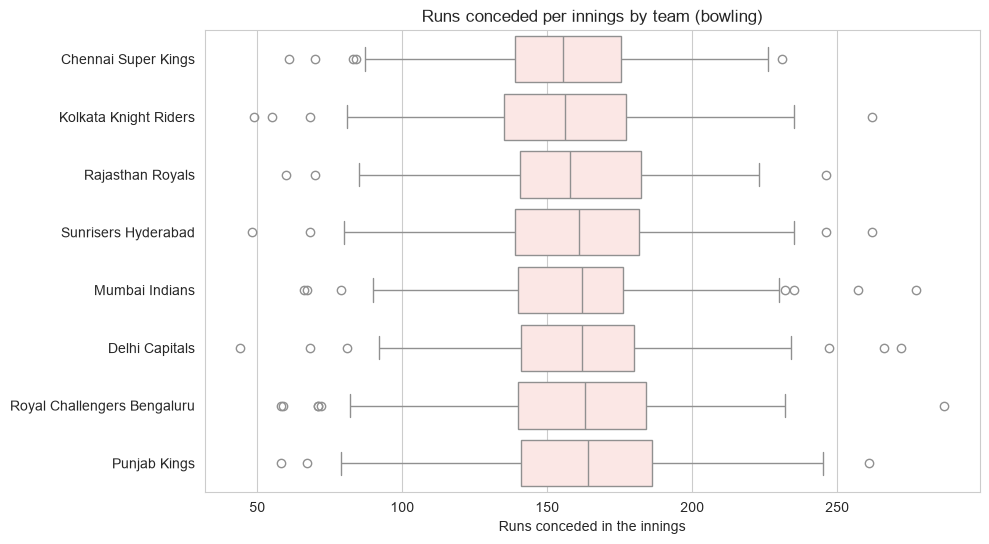

,median,mean,std
bowling_team,,,
Chennai Super Kings,155.5,156.2,30.5
Kolkata Knight Riders,156.0,156.0,32.9
Rajasthan Royals,158.0,159.6,30.8
Sunrisers Hyderabad,161.0,160.9,34.2
Mumbai Indians,162.0,158.7,31.3
Delhi Capitals,162.0,160.3,32.7
Royal Challengers Bengaluru,163.0,160.8,35.0
Punjab Kings,164.0,162.7,33.8


In [15]:
# B3. runs conceded per innings for each team (bowling)
conceded = (bb.groupby(["match_id", "inning", "bowling_team"])["total_runs"].sum()
              .reset_index(name="runs_conceded"))

order = conceded.groupby("bowling_team")["runs_conceded"].median().sort_values().index

plt.figure(figsize=(10, 6))
sns.boxplot(data=conceded, x="runs_conceded", y="bowling_team", order=order, color="mistyrose")
plt.title("Runs conceded per innings by team (bowling)")
plt.xlabel("Runs conceded in the innings"); plt.ylabel("")
plt.show()

conceded.groupby("bowling_team")["runs_conceded"].agg(["median", "mean", "std"]).loc[order].round(1)

**Observation:** Mumbai Indians hit the most sixes (6.57 per innings) and Delhi Capitals the fewest (5.13) – a gap of about 1.4 sixes, or roughly 9 runs, per innings. Rajasthan Royals hit the most fours (14.10) but relatively few sixes. Fours vary much less between teams (13.2–14.1) than sixes do.

### EDA summary
**Match level**
1. Scoring rises through the innings and is highest at the Death (9.96 runs per over), where wickets also fall twice as fast.
2. The Death is faster than the Powerplay because of fewer dot balls, not more boundaries.
3. A typical innings total is about 160, and totals are symmetrically distributed.

**Team level**
1. Only CSK, MI and KKR win more than half their matches; DC and PBKS are the weakest.
2. All 8 teams post very similar typical totals, so runs scored alone does not separate winners from losers.
3. Teams differ more in six-hitting (5.1–6.6 per innings) than in four-hitting.

## 4. Team Performance Profiles (Bivariate / Multivariate Analysis)

Here we look at how two or more variables relate for each franchise.
- **Batting:** run rate and dot-ball % of balls faced.
- **Bowling:** economy, balls per wicket (bowling strike rate) and dot-ball % bowled.
- **Result:** win % (from Part B1).

In [16]:
# batting record of each team
bat = bb.groupby("batting_team").agg(runs=("total_runs", "sum"), balls=("legal", "sum"),
                                     dots=("is_dot", "sum"))
bat["bat_run_rate"] = bat["runs"] / bat["balls"] * 6
bat["bat_dot_%"] = bat["dots"] / bat["balls"] * 100

# bowling record of each team
bowl = bb.groupby("bowling_team").agg(conceded=("bowler_runs", "sum"), balls=("legal", "sum"),
                                      wkts=("bowler_wkt", "sum"), dots=("is_dot", "sum"))
bowl["economy"] = bowl["conceded"] / bowl["balls"] * 6
bowl["balls_per_wkt"] = bowl["balls"] / bowl["wkts"]
bowl["bowl_dot_%"] = bowl["dots"] / bowl["balls"] * 100

team = (bat[["bat_run_rate", "bat_dot_%"]]
        .join(bowl[["economy", "balls_per_wkt", "bowl_dot_%"]])
        .join(team_record["win_%"]))
team.index.name = "team"
team = team.sort_values("win_%", ascending=False)
team.round(2)

,bat_run_rate,bat_dot_%,economy,balls_per_wkt,bowl_dot_%,win_%
team,,,,,,
Chennai Super Kings,8.38,35.33,7.96,20.05,36.54,59.13
Mumbai Indians,8.45,36.66,8.05,20.85,36.55,56.50
Kolkata Knight Riders,8.31,36.79,8.04,21.71,36.28,51.60
Rajasthan Royals,8.23,36.66,8.15,22.07,35.67,49.48
Sunrisers Hyderabad,8.31,34.33,8.22,21.60,36.07,47.85
Royal Challengers Bengaluru,8.34,36.09,8.31,21.55,35.78,46.51
Punjab Kings,8.38,35.92,8.41,21.75,35.44,44.34
Delhi Capitals,8.11,35.81,8.18,21.54,35.59,43.93


**Observation:**
- The **4 teams with the best bowling economy (CSK 7.96, KKR 8.04, MI 8.05, RR 8.15) are exactly the 4 with the highest win %**.
- Batting run rates are very close (8.11 to 8.45). Punjab Kings bat as fast as CSK (8.38) but have the **worst economy (8.41)** and one of the lowest win % (44.3%).
- Sunrisers Hyderabad have the lowest batting dot-ball % (34.3%), yet a below-average win %.

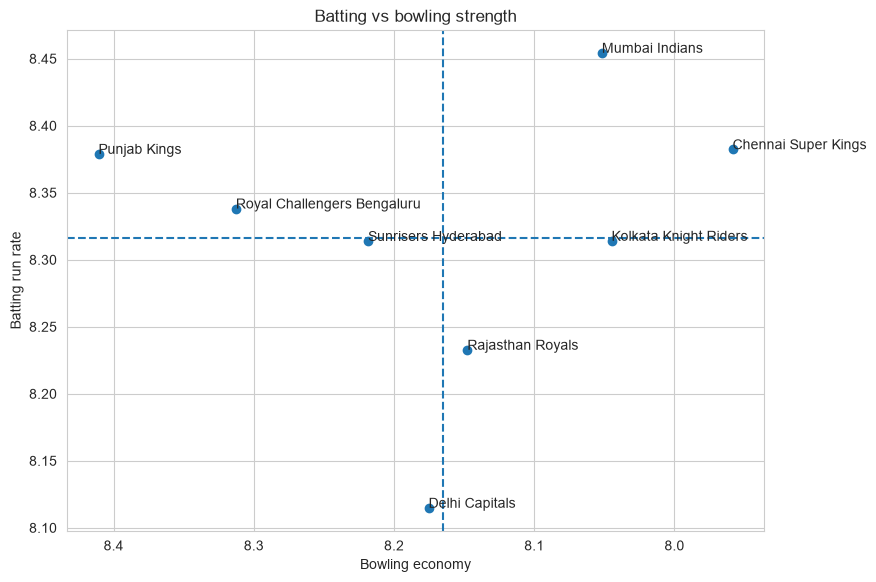

In [26]:
plt.figure(figsize=(9, 6.5))

plt.scatter(team["economy"], team["bat_run_rate"])

for name in team.index:
    plt.text(
        team.loc[name, "economy"],
        team.loc[name, "bat_run_rate"],
        name
    )

plt.axvline(team["economy"].mean(), linestyle="--")
plt.axhline(team["bat_run_rate"].mean(), linestyle="--")

plt.gca().invert_xaxis()

plt.xlabel("Bowling economy")
plt.ylabel("Batting run rate")
plt.title("Batting vs bowling strength")

plt.show()

**How to read the chart:** the dashed lines are the averages of the 8 teams (batting run rate ≈ 8.31, economy ≈ 8.17). **Top-right** = above average at both batting and bowling.

**Observation:** CSK and MI sit in the top-right – strong at both. Punjab Kings and RCB bat well but bowl poorly (top-left), and both win less than half their matches. Rajasthan Royals bowl better than average but bat slower. Delhi Capitals are below average at both, matching their lowest win %.

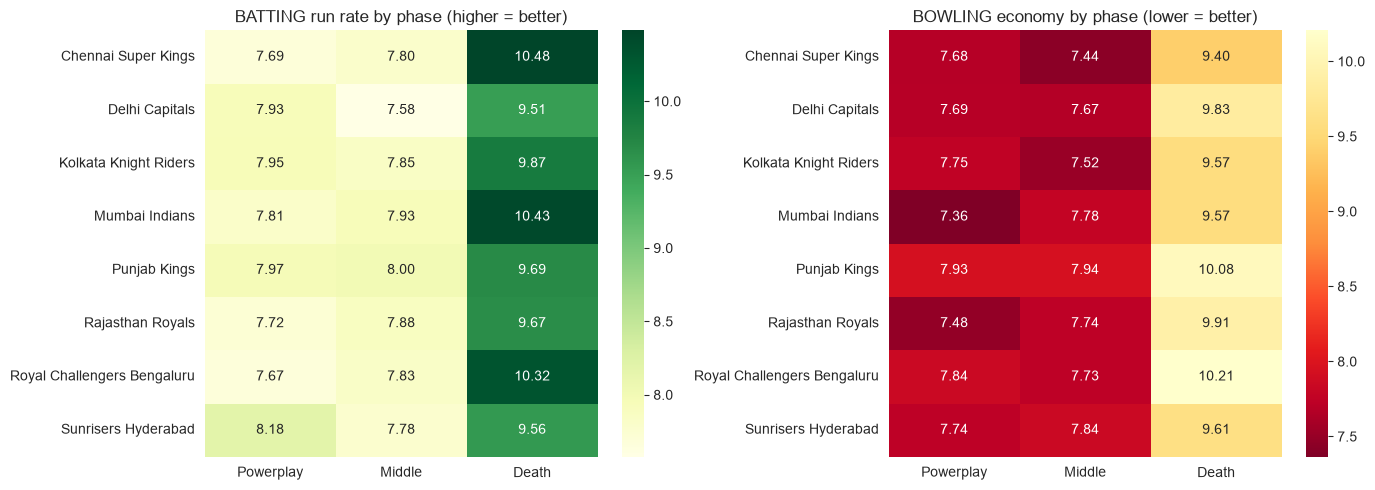

In [ ]:
# batting run rate and bowling economy in each phase
bp = bb.groupby(["batting_team", "phase"])[["total_runs", "legal"]].sum()
bat_phase = (bp["total_runs"] / bp["legal"] * 6).unstack()

wp = bb.groupby(["bowling_team", "phase"])[["bowler_runs", "legal"]].sum()
bowl_phase = (wp["bowler_runs"] / wp["legal"] * 6).unstack()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(bat_phase, annot=True, fmt=".2f", cmap="YlGn", ax=ax[0])
ax[0].set_title("BATTING run rate by phase (higher = better)")
ax[0].set_xlabel(""); ax[0].set_ylabel("")
sns.heatmap(bowl_phase, annot=True, fmt=".2f", cmap="YlOrRd_r", ax=ax[1])
ax[1].set_title("BOWLING economy by phase (lower = better)")
ax[1].set_xlabel(""); ax[1].set_ylabel("")
plt.tight_layout()
plt.show()

**Observation:**
- **Death batting:** CSK (10.48), MI (10.43) and RCB (10.32) are strongest; Delhi Capitals (9.51) and Sunrisers Hyderabad (9.56) are weakest.
- **Powerplay batting:** Sunrisers Hyderabad are the fastest starters (8.18).
- **Powerplay bowling:** Mumbai Indians (7.36) and Rajasthan Royals (7.48) are the most economical; Punjab Kings (7.93) the least.
- **Middle and Death bowling:** CSK are the best in both (7.44 and 9.40). RCB (10.21) and Punjab Kings (10.08) concede the most at the Death.

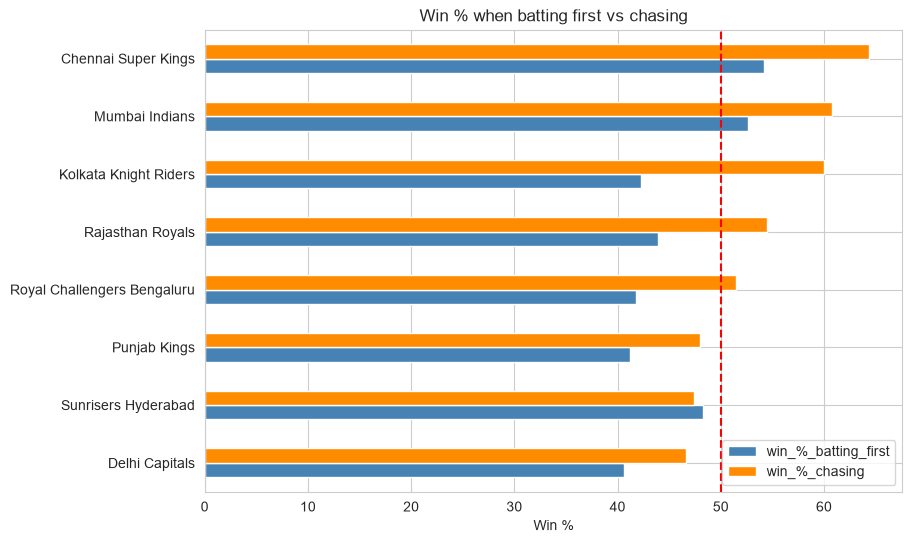

,win_%_batting_first,win_%_chasing
batting_team,,
Delhi Capitals,40.6,46.6
Sunrisers Hyderabad,48.2,47.4
Punjab Kings,41.2,48.0
Royal Challengers Bengaluru,41.8,51.4
Rajasthan Royals,44.0,54.5
Kolkata Knight Riders,42.3,60.0
Mumbai Indians,52.6,60.7
Chennai Super Kings,54.2,64.4


In [19]:
# win % when batting first vs chasing, for each team
role = (inn.groupby(["batting_team", "inning"])["won"].mean() * 100).unstack()
role.columns = ["win_%_batting_first", "win_%_chasing"]
role = role.sort_values("win_%_chasing")

role.plot(kind="barh", figsize=(9, 6), color=["steelblue", "darkorange"])
plt.axvline(50, color="red", linestyle="--")
plt.title("Win % when batting first vs chasing")
plt.xlabel("Win %"); plt.ylabel("")
plt.show()
role.round(1)

**Observation:** 7 of the 8 teams win more often when chasing. CSK win 64.4% of chases, and KKR show the biggest gap (60.0% chasing vs 42.3% batting first). Sunrisers Hyderabad are the only exception, with almost equal records (48.2% vs 47.4%).

## 5. Hypothesis Testing

- Significance level: **α = 0.05**. If p-value < 0.05 we reject H0.

| # | Question | Test |
|---|---|---|
| H1 | Do winning innings have a lower dot-ball %? | Two-sample t-test (Welch) |
| H2 | Is run rate different when batting first vs chasing? | Two-sample t-test (Welch) |
| H3 | Is losing 3+ wickets in the Powerplay linked to losing? | Chi-square Degree of Association |
| H4 | Do the 8 franchises differ in batting run rate? | One-way ANOVA |

### H1: Winning innings have a lower dot-ball %
- **H0:** Mean dot-ball % is the same in winning and losing innings
- **H1:** Mean dot-ball % is different in winning and losing innings

In [37]:
t, p = stats.ttest_ind(inn.loc[inn["won"] == 1, "dot_pct"], inn.loc[inn["won"] == 0, "dot_pct"], equal_var=False)
print(f"t = {t:.2f}, p-value = {p:.4g}")
print("Reject H0 (significant difference)" if p < 0.05 else "Fail to reject H0 (no significant difference)")

t = -10.82, p-value = 2.174e-26
Reject H0 (significant difference)


Result:
Winning innings have a dot-ball % of 34.15%, losing innings 38.02%. p-value is less than 0.05, so we reject H0. 

### H2: Run rate is different when batting first vs chasing
- **H0:** Mean run rate is the same in the 1st and 2nd innings
- **H1:** Mean run rate is different in the 1st and 2nd innings

In [39]:
t, p = stats.ttest_ind(inn.loc[inn["inning"] == 1, "run_rate"], inn.loc[inn["inning"] == 2, "run_rate"], equal_var=False)
print(f"t = {t:.2f}, p-value = {p:.4g}")
print("Reject H0 (significant difference)" if p < 0.05 else "Fail to reject H0 (no significant difference)")

t = 1.53, p-value = 0.1272
Fail to reject H0 (no significant difference)


Result: 
1st innings run rate 8.39, 2nd innings 8.28. p-value = 0.127 > 0.05, so we fail to reject H0.

### H3: Losing 3+ wickets in the Powerplay is linked to losing the match
- **H0:** The match result is independent of whether the batting team lost 3+ wickets in the Powerplay
- **H1:** The match result depends on it

Both variables are categorical (collapse yes/no, won yes/no), so we use a chi-square degree of association.

In [35]:
inn["pp_collapse"] = np.where(inn["pp_wkts"] >= 3, "3+ yes", "3+ no")

table = pd.crosstab(inn["pp_collapse"], inn["won"])
table.columns = ["Lost", "Won"]
print(table)
ans = stats.chi2_contingency(table)
print(f"\np-value = {ans.pvalue:.4g}")
print("->", "Reject H0 (result depends on Powerplay collapse)" if ans.pvalue < 0.05 else "Fail to reject H0")

             Lost  Won
pp_collapse           
3+ no         621  759
3+ yes        202   64

p-value = 4.561e-20
-> Reject H0 (result depends on Powerplay collapse)


Result: Teams that lose 3+ wickets in the Powerplay win less number of the time, compared with teams losing less than 3 wickets. p-value is less than 0.05, so we reject H0: a Powerplay collapse is strongly linked to losing.

### H4: The 8 franchises differ in batting run rate
- **H0:** All 8 franchises have the same mean innings run rate
- **H1:** At least one franchise has a different mean

We compare more than two groups, so we use **one-way ANOVA**.

In [ ]:
groups = [inn.loc[inn["batting_team"] == t, "run_rate"] for t in TEAMS]
f, p = stats.f_oneway(*groups)
print(f"F = {f:.2f}, p-value = {p:.2f}")
print("->", "Reject H0 (franchises differ)" if p < 0.05 else "Fail to reject H0 (no significant difference between franchises)")

inn.groupby("batting_team")["run_rate"].agg(["mean", "count"]).sort_values("mean", ascending=False).round(2)

F = 1.04, p-value = 0.4008
-> Fail to reject H0 (no significant difference between franchises)


,mean,count
batting_team,,
Mumbai Indians,8.48,223
Punjab Kings,8.41,212
Chennai Super Kings,8.37,208
Royal Challengers Bengaluru,8.37,215
Kolkata Knight Riders,8.33,219
Sunrisers Hyderabad,8.33,163
Rajasthan Royals,8.23,192
Delhi Capitals,8.14,214


**Result:** F = 1.04, p-value = 0.401 (above 0.05), so we **fail to reject H0**. The franchises' average batting run rates (8.14 to 8.48). The differences between teams show up in bowling and in specific phases

### Summary of hypothesis tests

| # | Hypothesis | p-value | Decision |
|---|---|---|---|
| H1 | Dot-ball % differs in winning vs losing innings| ≈ 0 | **Reject H0** |
| H2 | Run rate differs batting first vs chasing | 0.127 | Fail to reject H0 |
| H3 | Match result depends on a Powerplay collapse | ≈ 0 | **Reject H0** |
| H4 | Batting run rate differs across the 8 franchises | 0.401 | Fail to reject H0 |

## 6. Business Insights

1. **The Death overs are where matches swing.**
2. **Scoring comes from avoiding dot balls, not only from boundaries.**
3. **Dot balls are linked to losing.**
4. **A Powerplay collapse increase the chance of winning**
5. **Bowling separates winners more than batting.** 
6. **Chasing teams win more often, but not because they score faster**

## 7. Recommendations

**For franchise management and the auction team**
1. **Prioritise bowling, especially economical Death bowlers.** Bowling economy is the clearest difference between successful and unsuccessful franchises. RCB (10.21) and Punjab Kings (10.08) concede the most at the Death and should target Death specialists.
2. **Protect the Powerplay.** Invest in top-order batters who survive the first 6 overs; losing 3+ wickets there cuts the win rate in half.
3. **Reduce dot balls.** Train strike rotation, especially in the Middle overs, and value batters who keep the scoreboard moving – not only big hitters.
4. **Fix team-specific weak phases.** Delhi Capitals and Sunrisers Hyderabad need Death-over hitters (9.51 and 9.56 runs per over); Punjab Kings need Powerplay bowling (7.93 economy, the worst of the 8).
5. **Prefer chasing when conditions allow**, since 7 of 8 franchises win more often when chasing – but treat this as a tendency, not a guaranteed advantage.

**Limitations**
- Only matches between the 8 long-running franchises are included; Gujarat Titans and Lucknow Super Giants were excluded because of their small number of matches.
- Sunrisers Hyderabad joined in 2013, so they have fewer matches (163) than the others.